<a href="https://colab.research.google.com/github/SkrybaOtis/Systemy_AI/blob/main/SystemyAI_Lab8_FashionMNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Systemy AI – Laboratorium 8
## Zadanie: sieć neuronowa dla Fashion-MNIST

**Fashion-MNIST** to „trudniejszy MNIST”: 70 000 zdjęć ubrań 28 × 28 pikseli w 10 klasach (koszulka, spodnie, sweter, sukienka, płaszcz, sandał, koszula, sneakers, torebka, botek). Format jest identyczny jak w MNIST, więc kod z wzoru (`SystemyAI_Lab8_wzor.ipynb`) przenosi się prawie bez zmian – ale wyniki będą inne.

Twoje zadanie: porównać regresję softmax z dwiema sieciami, wybrać model na zbiorze walidacyjnym, ocenić go raz na teście i sprawdzić, które ubrania model myli.

**Czas:** każdy model uczy się 5 epok, ok. 30–60 s na CPU w Colabie.

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Dane
1. Wczytaj `datasets.FashionMNIST` (`root="data"`, `download=True`, `transform=transforms.ToTensor()`) – część treningową do `train_full`, testową do `test_set`.
2. Podziel `train_full` na `train_set` (50 000) i `val_set` (10 000): `random_split(..., generator=torch.Generator().manual_seed(42))`.
3. Utwórz `train_loader` (batch 128, `shuffle=True`), `val_loader` i `test_loader` (batch 1000).
4. Wyświetl 10 pierwszych obrazów treningowych z **nazwami** klas z listy `klasy` poniżej.

In [1]:
klasy = ["koszulka", "spodnie", "sweter", "sukienka", "płaszcz",
         "sandał", "koszula", "sneakers", "torebka", "botek"]

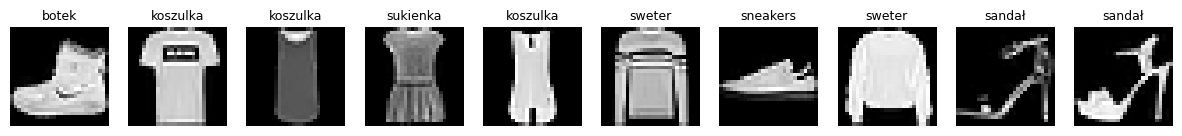

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

train_full = datasets.FashionMNIST(root="data", train=True, download=True, transform=transforms.ToTensor())
test_set = datasets.FashionMNIST(root="data", train=False, download=True, transform=transforms.ToTensor())

train_set, val_set = random_split(train_full, [50_000, 10_000],
                                  generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
val_loader = DataLoader(val_set, batch_size=1000)
test_loader = DataLoader(test_set, batch_size=1000)

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for ax, i in zip(axes, range(10)):
    img, lab = train_full[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(klasy[lab], fontsize=9)
    ax.axis("off")
plt.show()

In [3]:
# TEST
assert len(train_set) == 50_000 and len(val_set) == 10_000 and len(test_set) == 10_000
assert tuple(train_full[0][0].shape) == (1, 28, 28)
print("1 OK")

1 OK


---
## 2. Funkcje uczenia i oceny
Napisz (lub przenieś z wzoru i zrozum!) trzy funkcje:
- `epoka_uczenia(model, loader, optimizer)` – jedna epoka uczenia z `model.train()`,
- `ocen(model, loader)` – zwraca `(strata, accuracy)` z `model.eval()` i `torch.no_grad()`,
- `trenuj(model, epochs=5, lr=1e-3)` – optymalizator Adam; po każdej epoce zapisuje accuracy na train i val w słowniku z kluczami `"train acc"`, `"val acc"` i go zwraca.

In [4]:
loss_fn = nn.CrossEntropyLoss()


def epoka_uczenia(model, loader, optimizer):
    model.train()
    for xb, yb in loader:
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()


def ocen(model, loader):
    """Zwraca (strata, accuracy) na danym zbiorze."""
    model.eval()
    suma_straty, trafione, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            logity = model(xb)
            suma_straty += loss_fn(logity, yb).item() * len(yb)
            trafione += (logity.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return suma_straty / n, trafione / n


def trenuj(model, epochs=5, lr=1e-3):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    historia = {"train acc": [], "val acc": []}
    start = time.time()
    for e in range(epochs):
        epoka_uczenia(model, train_loader, optimizer)
        historia["train acc"].append(ocen(model, train_loader)[1])
        historia["val acc"].append(ocen(model, val_loader)[1])
        print(f"epoka {e + 1}: train acc {historia['train acc'][-1]:.4f}, val acc {historia['val acc'][-1]:.4f}")
    print(f"czas: {time.time() - start:.0f} s")
    return historia

---
## 3. Model bazowy: regresja softmax
`torch.manual_seed(0)`, potem `model_soft = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))` i `hist_soft = trenuj(model_soft)`.

In [5]:
torch.manual_seed(0)
model_soft = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
hist_soft = trenuj(model_soft)

epoka 1: train acc 0.8159, val acc 0.8105
epoka 2: train acc 0.8308, val acc 0.8282
epoka 3: train acc 0.8445, val acc 0.8386
epoka 4: train acc 0.8465, val acc 0.8376
epoka 5: train acc 0.8519, val acc 0.8458
czas: 69 s


In [6]:
# TEST
assert len(hist_soft["val acc"]) == 5
assert 0.78 < hist_soft["val acc"][-1] < 0.88
print("3 OK")

3 OK


---
## 4. Dwie sieci
Przed każdym modelem `torch.manual_seed(0)`:
- `model_maly`: `Flatten → Linear(784, 128) → ReLU → Linear(128, 10)` → `hist_maly`,
- `model_duzy`: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)` → `hist_duzy`.

Zbierz wyniki trzech modeli w `pd.DataFrame` o nazwie `wyniki` (indeks: `"softmax"`, `"sieć mała"`, `"sieć duża"`; kolumny: `"parametry"`, `"train acc"`, `"val acc"` – wartości po ostatniej epoce) i narysuj krzywe **val acc** wszystkich trzech modeli na jednym wykresie.

epoka 1: train acc 0.8443, val acc 0.8404
epoka 2: train acc 0.8608, val acc 0.8557
epoka 3: train acc 0.8686, val acc 0.8570
epoka 4: train acc 0.8761, val acc 0.8686
epoka 5: train acc 0.8745, val acc 0.8626
czas: 66 s
epoka 1: train acc 0.8492, val acc 0.8410
epoka 2: train acc 0.8627, val acc 0.8615
epoka 3: train acc 0.8855, val acc 0.8724
epoka 4: train acc 0.8831, val acc 0.8725
epoka 5: train acc 0.8974, val acc 0.8817
czas: 71 s


,parametry,train acc,val acc
softmax,7850,0.8519,0.8458
sieć mała,101770,0.8745,0.8626
sieć duża,235146,0.8974,0.8817


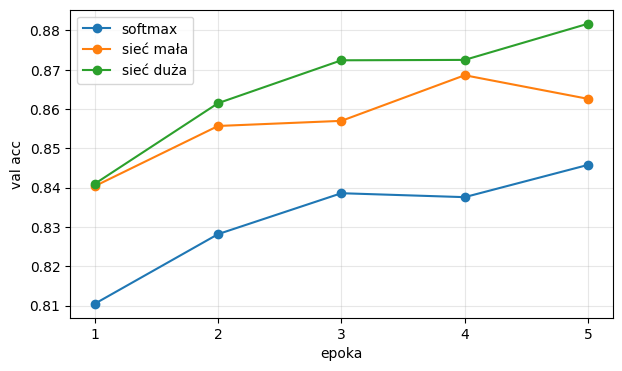

In [7]:
torch.manual_seed(0)
model_maly = nn.Sequential(nn.Flatten(),
                           nn.Linear(784, 128), nn.ReLU(),
                           nn.Linear(128, 10))
hist_maly = trenuj(model_maly)

torch.manual_seed(0)
model_duzy = nn.Sequential(nn.Flatten(),
                           nn.Linear(784, 256), nn.ReLU(),
                           nn.Linear(256, 128), nn.ReLU(),
                           nn.Linear(128, 10))
hist_duzy = trenuj(model_duzy)

liczba_param = lambda m: sum(p.numel() for p in m.parameters())

modele = {"softmax": (model_soft, hist_soft),
          "sieć mała": (model_maly, hist_maly),
          "sieć duża": (model_duzy, hist_duzy)}

wyniki = pd.DataFrame.from_dict(
    {nazwa: {"parametry": liczba_param(m),
             "train acc": h["train acc"][-1],
             "val acc": h["val acc"][-1]}
     for nazwa, (m, h) in modele.items()},
    orient="index")

display(wyniki.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
for nazwa, (m, h) in modele.items():
    ax.plot(range(1, 6), h["val acc"], "o-", label=nazwa)
ax.set_xlabel("epoka"); ax.set_ylabel("val acc"); ax.set_xticks(range(1, 6))
ax.legend(); ax.grid(alpha=0.3)
plt.show()

In [8]:
# TEST
assert list(wyniki.index) == ["softmax", "sieć mała", "sieć duża"]
assert wyniki.loc["sieć mała", "parametry"] == 101_770 and wyniki.loc["sieć duża", "parametry"] == 235_146
assert wyniki.loc["sieć mała", "val acc"] > wyniki.loc["softmax", "val acc"]
print("4 OK")

4 OK


*Twoja odpowiedź:*

1. Ile zyskuje sieć względem softmaksu na Fashion-MNIST, a ile zyskiwała na MNIST (wzór)? Skąd różnica?
> Na Fashion-MNIST sieć zyskuje ok. 3 punkty procentowe (softmax ≈ 0,85 → sieć mała ≈ 0,86 → sieć duża ≈ 0,88), czyli błąd spada z ok. 15% do ok. 12%.
> Na MNIST zysk był większy: 0,913 → 0,962 (+5 p.p.), a błąd spadł ponad dwukrotnie.
> Różnica wynika z tego, że cyfry mają prostsze granice dzięki czemu w tak małej rozdzielczości są wyraźniejsze niż obrazki ubrań.

2. Czy duża sieć jest wyraźnie lepsza od małej? Czy 2,3 razy więcej parametrów się opłaca?
> Duża sieć jest nieznacznie lepsza (niecałe 2 p.p. na val).
> 2,3× więcej parametrów zwykle się więc nie opłaca

3. Porównaj train acc i val acc dla każdego modelu. Gdzie różnica jest największa i co może oznaczać?
> Największa różnica jest dla dużej sieci, a sama różnica rośnie wraz z wielkością modelu. Może to oznaczać początek przeuczenia: model zaczyna zapamiętywać zbiór treningowy, więc na danych, których nie widział, radzi sobie gorzej.

---
## 5. Ocena końcowa i błędy
1. `najlepszy` – nazwa modelu z najwyższym `val acc` w tabeli `wyniki`; `model_koncowy` – ten model.
2. `acc_test` – accuracy na zbiorze **testowym** (jedyny raz, kiedy go używasz).
3. Zbierz predykcje dla całego zbioru testowego (`y_true`, `y_pred` jako tablice NumPy) i narysuj macierz pomyłek z nazwami klas (`ConfusionMatrixDisplay.from_predictions`, `xticks_rotation=45`).
4. Wypisz 3 pary klas (prawdziwa → przewidziana), które model myli najczęściej.

najlepszy model: sieć duża
test accuracy: 0.8751


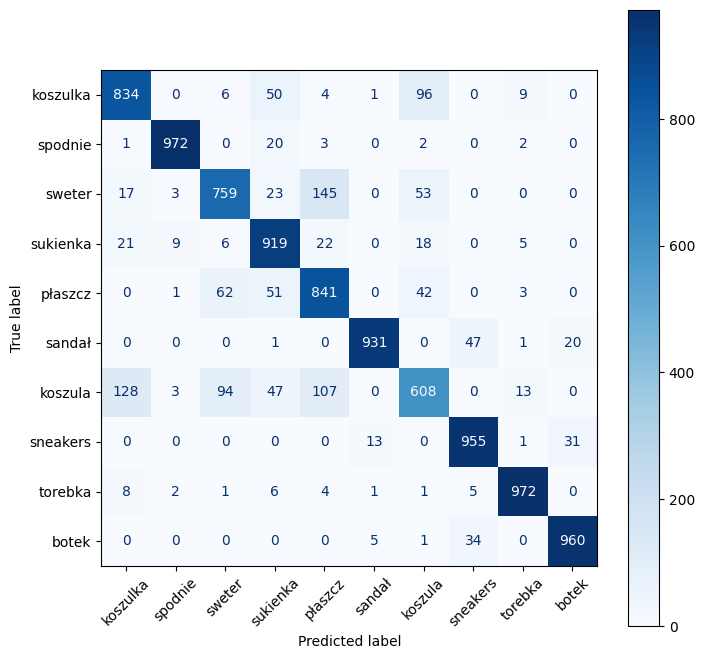

Najczęstsze pomyłki (prawdziwa → przewidziana):
  sweter → płaszcz: 145 razy
  koszula → koszulka: 128 razy
  koszula → płaszcz: 107 razy


In [9]:
najlepszy = wyniki["val acc"].idxmax()
model_koncowy = modele[najlepszy][0]
print("najlepszy model:", najlepszy)

strata_test, acc_test = ocen(model_koncowy, test_loader)
print(f"test accuracy: {acc_test:.4f}")

model_koncowy.eval()
listy_true, listy_pred = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        listy_pred.append(model_koncowy(xb).argmax(dim=1))
        listy_true.append(yb)
y_true = torch.cat(listy_true).numpy()
y_pred = torch.cat(listy_pred).numpy()

fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=klasy,
                                        xticks_rotation=45, cmap="Blues", ax=ax)
plt.show()

cm = confusion_matrix(y_true, y_pred)
np.fill_diagonal(cm, 0)
print("Najczęstsze pomyłki (prawdziwa → przewidziana):")
for idx in np.argsort(cm, axis=None)[::-1][:3]:
    i, j = np.unravel_index(idx, cm.shape)
    print(f"  {klasy[i]} → {klasy[j]}: {cm[i, j]} razy")

In [10]:
# TEST
assert najlepszy == wyniki["val acc"].idxmax()
assert 0.82 < acc_test < 0.92
assert len(y_true) == len(y_pred) == 10_000
print("5 OK")

5 OK


*Twoja odpowiedź:*

1. Które klasy model myli najczęściej?
  Model myli najczęściej klasy, które mają podobny kształt/fason:
  - sweter → płaszcz
  - koszula → koszulka
  - koszula → płaszcz

2. Czy człowiek też miałby z nimi kłopot na obrazku 28 × 28?
  Przy tak małej rozdzielczości sam byłem mocno niepewny, czy w początkowej próbce 10 obrazków, to co myślę, że widzę jest tym w rzeczywistości. W związku z tym tak, człowiek też miałby kłopot.

3. Która klasa jest najłatwiejsza i dlaczego?
  Najłatiwejsze klasy (bo w tym przypadku są dwie „ex aequo”) to spodnie i torebka, bo mają unikalny, wyraźny i łatwo rozpoznawalny kształt w porównaniu do reszty klas.

---
## 6. Dla chętnych
1. Naucz `model_duzy` od nowa przez **15 epok** i narysuj train acc i val acc. Od której epoki krzywe zaczynają się rozjeżdżać? (To przeuczenie – temat następnych zajęć.)
2. Zamień `ReLU` na `Sigmoid` w małej sieci. Jak zmienia się szybkość uczenia?
3. Narysuj 10 obrazów testowych, na których model się pomylił, z podpisem „przewidziane (prawdziwe)”.